# Lab: Comparing Distributions Across Groups

Choose a new documented dataset with **at least one categorical feature and three quantitative features**. Develop and answer **three distinct research questions**, each comparing the distribution of a different quantitative feature across categorical groups. Use the six-step reproducible analysis workflow for each question, as in the Billboard lecture.

Your dataset must not have been used in any class demonstration or lab, including your own earlier lab submissions.


## Learning goals

- Select and document a new dataset suitable for comparing distributions.
- Distinguish meaningful quantitative measurements from identifiers and category codes.
- Develop three questions and record predictions before analyzing their results.
- Compare group sizes, center, spread, shape, overlap, and unusual observations.
- Check calculations against original records and write supported conclusions and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do original records support the calculation and interpretation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each question. Inspect the dataset once, then explain the observations, features, and preparation relevant to each investigation. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI for questions, debugging, or feedback. You remain responsible for understanding the code, reading the actual source documentation, and checking claims against your output. Disclose AI use and describe a suggestion you checked in the final reflection.


## Find and document a new dataset

Choose a manageable CSV from a documented source, such as a government open-data portal, a research repository, or Kaggle. It must have:

- A named publisher or creator and a data dictionary or equivalent feature documentation.
- At least one meaningful categorical feature with two or more groups containing multiple observations.
- At least three distinct quantitative measurements with documented meanings and units. Numeric IDs, category codes, and alternate-unit copies of the same measurement do not count as three quantitative features.
- Enough usable observations in each comparison group to examine distributions. There is no universal minimum group size for this descriptive exercise; justify exclusions and acknowledge sparse groups.
- A topic and dataset that have not already been used in class or any lab. A different filename, subset, or download of a previously used dataset does not make it new.

Review the course notebooks and your previous submissions. Examples already used include Billboard number-one songs, Titanic passengers, Pokémon, and penguins; this is not an exhaustive list.

Save the CSV in this notebook's `data` folder, use a relative path, and preserve the original records. Use a descriptive DataFrame name ending in `_df`. Your categorical feature can be reused across questions, or you may choose different categorical features for different questions.


**What are the dataset title, publisher or creator, direct source URL, data dictionary URL or location, and access date?**

Your answer: The dataset is Nintendo Switch Games Reviews, created and published on Kaggle by Giovanni60310. The direct source is https://www.kaggle.com/datasets/giovanni60310/nintendo-switch-games-reviews. The data dictionary is the “Column Description” section on that same Kaggle page, which defines each of the 14 columns. I accessed the dataset on November 5, 2026.

**Describe the dataset: what does one row represent, what time period and population or location does it cover, and how were observations collected? State when something is undocumented.**

Your answer: One row represents one Nintendo Switch game review published on Nintendo Life, not one individual user’s review. The dataset has 637 rows, and the games’ release dates run from 2017 through 2022. The population is Switch games that Nintendo Life reviewed, so it is not a complete or random sample of all Switch games. The creator says the data were scraped with Python from https://www.nintendolife.com/reviews. The page does not document the exact scrape date, how games were selected beyond being reviewed, or a geographic location; those details are undocumented. The Kaggle page was last updated on September 28, 2022.

**How did you confirm this dataset has not been used in class or any earlier lab, including your own submissions?**

Your answer: I searched the class repo for the dataset file name and did not find it in any lecture, lab, or earlier submission.

## Load and inspect the data

Use separate cells to import the libraries, load the CSV, and inspect its structure. Identify special missing codes from the dictionary; distinguish them from valid zeros.


In [1]:
# Import Pandas, Matplotlib pyplot, and Seaborn with conventional aliases.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Load your CSV into a descriptive DataFrame ending in _df using a relative path.
switch_games_df = pd.read_csv("data/switch-games.csv")

In [3]:
# Display the first five rows.
switch_games_df.head()

,id,title,game_url,image_url,system,publisher,developer,genre,num_players,release_date,review,review_conclusion,num_votes,rating
0,0f0191a3,The DioField Chronicle,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/d9a6ef84ec8cf/...,Nintendo Switch,Square Enix,Square Enix,RPG Simulation Strategy,1,22nd Sep 2022,Published by Square Enix and developed with as...,Despite its shortcomings The DioField Chronic...,0,0.0
1,f2af5f5f,The Legend of Heroes: Trails from Zero,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/004c2655b08cc/...,Nintendo Switch,NIS America,Nihon Falcom,RPG,1,27th Sep 2022,We dont blame you if you’re intimidated by Fal...,In a series renowned for its stellar writing ...,0,0.0
2,a8996117,NBA 2K23,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/60aff0dbdc402/...,Nintendo Switch,2K,Visual Concepts,Sports,4 (10 Online),9th Sep 2022,Its once again reached that time of year when ...,NBA 2K23 makes the inevitable downgrades and c...,2,0.0
3,e2f10932,Temtem,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/c6c585ce49b59/...,Nintendo Switch,Humble Games,Crema Games,Action Adventure RPG,1 (999 Online),6th Sep 2022,At the beginning of our Temtem adventure we h...,Even without the endgame content Temtem is wo...,5,7.8
4,51ff4f64,Made in Abyss: Binary Star Falling into Darkness,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/063177f5b67f4/...,Nintendo Switch,Spike Chunsoft US,Chime,Action RPG,1,2nd Sep 2022,Made in Abyss feels like an anime/manga ripe f...,Made in Abyss is an odd game to recommend; the...,2,0.0


In [4]:
# Display the last five rows.
switch_games_df.tail()

,id,title,game_url,image_url,system,publisher,developer,genre,num_players,release_date,review,review_conclusion,num_votes,rating
632,0f933f58,Skylanders Imaginators,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/83212dea254b0/...,Nintendo Switch,Activision,Toys for Bob,Action Adventure,2,3rd Mar 2017,Skylanders Imaginators may be a launch title o...,If you are looking for a family-friendly way t...,21,7.4
633,44b24a40,Just Dance 2017,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/1eafb4d828558/...,Nintendo Switch,Ubisoft,Ubisoft,Dancing Music,6,3rd Mar 2017,People all over the world have finally got the...,Just Dance 2017 is great at what it does – ser...,25,7.1
634,1e8edaf2,Super Bomberman R,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/cfd86c7a10b1b/...,Nintendo Switch,Konami,Konami,Action Puzzle,8,3rd Mar 2017,When most people pick up their Switch theyll ...,Super Bomberman R is a no-frills entry in a se...,205,6.8
635,92d53aa6,1-2-Switch,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/dc982b88045e5/...,Nintendo Switch,Nintendo,Nintendo,Party,2,3rd Mar 2017,Would the Wii have sold over 100 million units...,1-2-Switch does a great job of showing off the...,175,5.9
636,97fc82c2,The Legend of Zelda: Breath of the Wild,https://www.nintendolife.com/reviews/nintendo-...,https://images.nintendolife.com/e409aebf4d1f2/...,Nintendo Switch,Nintendo,Nintendo SPD,Action Adventure,1,3rd Mar 2017,The Legend of Zelda has always been a franchis...,The Legend of Zelda: Breath of the Wild is a l...,2 782,9.6


In [5]:
# Display the DataFrame shape.
switch_games_df.shape

(637, 14)

In [6]:
# Display .info().
switch_games_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 637 entries, 0 to 636
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 637 non-null    object 
 1   title              637 non-null    object 
 2   game_url           637 non-null    object 
 3   image_url          637 non-null    object 
 4   system             637 non-null    object 
 5   publisher          631 non-null    object 
 6   developer          627 non-null    object 
 7   genre              622 non-null    object 
 8   num_players        612 non-null    object 
 9   release_date       637 non-null    object 
 10  review             637 non-null    object 
 11  review_conclusion  627 non-null    object 
 12  num_votes          637 non-null    object 
 13  rating             637 non-null    float64
dtypes: float64(1), object(13)
memory usage: 69.8+ KB


In [7]:
# Display missing-value counts for every feature.
switch_games_df.isna().sum()

id                    0
title                 0
game_url              0
image_url             0
system                0
publisher             6
developer            10
genre                15
num_players          25
release_date          0
review                0
review_conclusion    10
num_votes             0
rating                0
dtype: int64

### Document the features

Complete one row for **every feature**. Add rows as needed. For data type, use categorical or quantitative, and explicitly identify identifiers and temporal features where appropriate. Report the actual Pandas storage type separately.


| Feature | Meaning and units or category codes | Data type | Data storage type | Missing values |
| --- | --- | --- | --- | ---: |
| id | Unique MD5 identifier for each review/game row; not a measurement. | Identifier | object | 0 |
| title | Game title; identifies the game. | Identifier | object | 0 |
| game_url | Nintendo Life review URL; identifies the source page. | Identifier | object | 0 |
| image_url | URL of the game image; identifies an image, not a measurement. | Identifier | object | 0 |
| system | Platform category: Nintendo Switch or Switch eShop. | Categorical | object | 0 |
| publisher | Game publisher name. | Categorical | object | 6 |
| developer | Game developer name | Categorical | object | 10 |
| genre | One or more genre labels separated by spaces, e.g. Action  Adventure | Categorical | object | 15 |
| num_players | Maximum player count in players. Stored as text such as 1, 4, or 4 (10 Online); the leading number is maximum offline players. | Quantitative | object | 25 |
| release_date | Release date as text | Temporal | object | 0 |
| review | Full review text; free text, not a measurement | Text (qualitative) | object | 0 |
| review_conclusion | Review conclusion text; free text, not a measurement. | Text (qualitative) | object | 10 |
| num_votes | Number of user votes; 0 means no votes and is valid. | Quantitative | object | 0 |
| rating | User rating on a 0–10 scale. 0 is a documented missing code when votes are below the threshold. | Quantitative | float64 | 0 blank; 51 zero-coded |

**Which categorical feature(s) and three quantitative features will you analyze? Why are they appropriate for distribution comparisons? Explain any missing codes or conversions.**

Your answer: I’ll compare three quantitative features: maximum offline players, number of user votes, and user rating. I’ll use two categorical features: broad genre and release year. I’ll group the multi-label genre field into broad families using the first listed genre, then use those families for the player-count and rating questions. For the votes question, I’ll pull the year from release_date. I’ll check the usable observations in each group before analyzing and note any sparse groups.

num_players is text like 4 (10 Online), so I’ll keep the leading number as maximum offline players and ignore the online count. I’ll exclude games with no player count. num_votes uses spaces as thousands separators, so I’ll remove them and convert it to integers; zero votes is valid. rating is on a 0–10 scale, but 0 is a documented missing code when votes are below the threshold, so I’ll exclude those rows instead of treating 0 as a real rating. I’m focusing on genre and release year rather than system, publisher, or developer.

## Plan three investigations

Write three specific questions. **Use a different quantitative feature for each question**, covering at least three in total. Each question must compare that feature's distribution across at least two categorical groups. You may reuse the same grouping feature. Changing only the plot type does not create a new question.

A useful question pattern is: “How does the distribution of [measurement and units] differ among [groups] in [documented population or period]?” Adapt it to your dataset's meaning. Similar distributions are a valid result; do not search for differences by repeatedly changing groups or discarding records.


## Investigation 1

### Step 1: Question


**What is research question 1? Name the quantitative feature, its units, and the categorical groups.**

Your answer: For my first question, I want to know how the number of players a game supports differs by genre. I’ll compare the distribution of maximum offline players across broad genre families: Action/Adventure, RPG, Sports/Racing, Strategy/Simulation, Party/Music, and Puzzle/Other. The quantitative feature is maximum offline players, measured in players, and the categorical feature is broad genre. The population is Nintendo Switch games reviewed by Nintendo Life.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect RPGs and Strategy/Simulation games to cluster at one player, since those genres are usually single-player. I expect Action/Adventure to be mostly one or two players, with some four-player co-op games, and Sports/Racing and Party/Music to sit higher, around four players with more spread. I also expect the distributions to be right-skewed because a few games support large player counts, and I expect a lot of overlap because many games in every genre are single-player.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I’ll use the game-review rows in switch_games_df, working from a copy so the original records stay intact. One analyzed observation is one Nintendo Switch game review, not one player or one vote. The quantitative feature is maximum offline players, measured in players, taken from the leading number in num_players; the online count in parentheses is ignored. The categorical feature is broad genre with six labels: Action/Adventure, RPG, Sports/Racing, Strategy/Simulation, Party/Music, and Puzzle/Other. I’ll exclude the 15 rows with no genre and the 25 rows with no player count. I’m not filtering on votes or rating for this question.

In [8]:
# Prepare this question's analysis DataFrame and preview the selected features.
q1_df = switch_games_df.copy()

genre_map = {
    "Action": "Action/Adventure",
    "Adventure": "Action/Adventure",
    "Platformer": "Action/Adventure",
    "Shooter": "Action/Adventure",
    "FPS": "Action/Adventure",
    "Fighting": "Action/Adventure",
    "Arcade": "Action/Adventure",
    "RPG": "RPG",
    "Strategy": "Strategy/Simulation",
    "Simulation": "Strategy/Simulation",
    "Sports": "Sports/Racing",
    "Racing": "Sports/Racing",
    "Driving": "Sports/Racing",
    "Party": "Party/Music",
    "Music": "Party/Music",
    "Dancing": "Party/Music",
}

def broad_genre(genre):
    if pd.isna(genre):
        return pd.NA
    first_word = genre.split()[0]
    return genre_map.get(first_word, "Puzzle/Other")

q1_df["broad_genre"] = q1_df["genre"].apply(broad_genre)
q1_df["max_offline_players"] = pd.to_numeric(
    q1_df["num_players"].str.extract(r"^(\d+)")[0],
    errors="coerce"
)

q1_df = q1_df.loc[
    q1_df["broad_genre"].notna() & q1_df["max_offline_players"].notna()
].copy()

genre_order = [
    "Action/Adventure",
    "RPG",
    "Sports/Racing",
    "Strategy/Simulation",
    "Party/Music",
    "Puzzle/Other",
]

q1_df[["title", "genre", "broad_genre", "num_players", "max_offline_players"]].head()

,title,genre,broad_genre,num_players,max_offline_players
0,The DioField Chronicle,RPG Simulation Strategy,RPG,1,1.0
1,The Legend of Heroes: Trails from Zero,RPG,RPG,1,1.0
2,NBA 2K23,Sports,Sports/Racing,4 (10 Online),4.0
3,Temtem,Action Adventure RPG,Action/Adventure,1 (999 Online),1.0
4,Made in Abyss: Binary Star Falling into Darkness,Action RPG,Action/Adventure,1,1.0


In [9]:
# Display the number of usable observations in each group.
q1_df["broad_genre"].value_counts().reindex(genre_order)

broad_genre
Action/Adventure       453
RPG                     47
Sports/Racing           44
Strategy/Simulation     20
Party/Music             25
Puzzle/Other            21
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


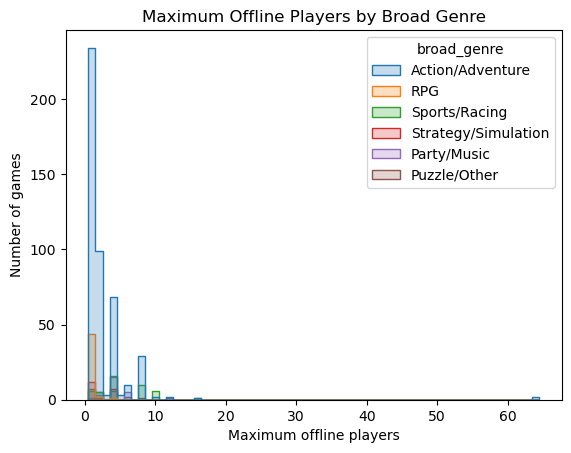

In [10]:
# Create and label the histogram comparison.
sns.histplot(
    data=q1_df,
    x="max_offline_players",
    hue="broad_genre",
    hue_order=genre_order,
    element="step",
    discrete=True,
)

plt.title("Maximum Offline Players by Broad Genre")
plt.xlabel("Maximum offline players")
plt.ylabel("Number of games")
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: The histogram was hard to read because the groups overlap a lot and Action/Adventure covers up most of the others. Action/Adventure has the tallest bars by far at 1 and 2 players. RPG and Strategy/Simulation look packed at 1 player, and I could see some Sports/Racing bars out near 10. Everything is bunched at the low end with a long right tail from a few games that support a lot of players, so I couldn't estimate the spreads well from the plot alone. The group sizes are very uneven — Action/Adventure has 453 games, while the other groups have 20 to 47 — so the smaller groups get short bars and are partly hidden.

In [11]:
# Display grouped .describe() summaries and calculate... 
q1_df.groupby("broad_genre")["max_offline_players"].describe().round(2).reindex(genre_order)

,count,mean,std,min,25%,50%,75%,max
broad_genre,,,,,,,,
Action/Adventure,453.0,2.67,4.64,1.0,1.0,1.0,4.0,64.0
RPG,47.0,1.11,0.48,1.0,1.0,1.0,1.0,4.0
Sports/Racing,44.0,5.36,3.45,1.0,3.5,4.0,8.0,16.0
Strategy/Simulation,20.0,2.10,1.45,1.0,1.0,1.0,4.0,4.0
Party/Music,25.0,4.36,2.06,1.0,4.0,4.0,4.0,12.0
Puzzle/Other,21.0,2.90,2.02,1.0,1.0,2.0,4.0,8.0


In [12]:
# or display the IQR for each group.
q1_iqr = (
    q1_df.groupby("broad_genre")["max_offline_players"].quantile(0.75)
    - q1_df.groupby("broad_genre")["max_offline_players"].quantile(0.25)
)

q1_iqr.reindex(genre_order)

broad_genre
Action/Adventure       3.0
RPG                    0.0
Sports/Racing          4.5
Strategy/Simulation    3.0
Party/Music            0.0
Puzzle/Other           3.0
Name: max_offline_players, dtype: float64

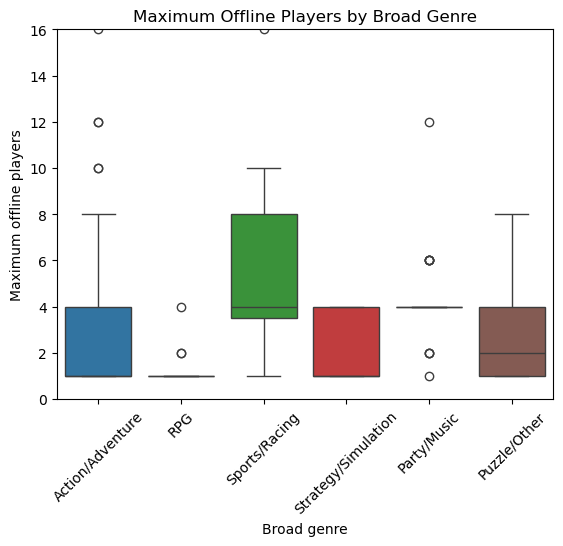

In [13]:
# Create and label the box-plot comparison.
sns.boxplot(
    data=q1_df,
    x="broad_genre",
    y="max_offline_players",
    hue = "broad_genre",
    order=genre_order,
    hue_order=genre_order,
)

plt.title("Maximum Offline Players by Broad Genre")
plt.xlabel("Broad genre")
plt.ylabel("Maximum offline players")
plt.xticks(rotation=45)
plt.ylim(0, 16)
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: My visual guesses mostly held up. Action/Adventure has a median of 1 player and an IQR of 3 players (from 1 to 4), so the typical game is single-player but the middle half reaches up to 4. RPG is the tightest group: median 1, IQR 0, and every game falls between 1 and 4 players. Strategy/Simulation has the same median and IQR as Action/Adventure but tops out at 4 players. Sports/Racing has the highest center, a median of 4 players and an IQR of 4.5 (3.5 to 8), with games up to 16. Party/Music is also centered at 4 with an IQR of 0, so most of those games sit right at 4, though one reaches 12. Puzzle/Other sits in between, with a median of 2 and an IQR of 3.

The box plot makes the centers and spreads much easier to compare than the histogram, and it shows that Action/Adventure’s box overlaps the small groups near 1 player. What it hides is how many games sit at each value — the histogram shows the big pile of Action/Adventure games at 1 and 2, while the box plot just shows one box. The histogram also shows the tail better, but the largest group covers the smaller ones. I limited the y-axis to 16 so the boxes are readable, and the two 64-player games are off-screen; the summaries still include them.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [14]:
# Perform a targeted check against original records or the declared group definitions.
q1_df.loc[q1_df["max_offline_players"] >= 16,
         ["title", "genre", "num_players", "broad_genre", "max_offline_players"]]
print("Original rows:", len(switch_games_df))
print("Missing genre:", switch_games_df["genre"].isna().sum())
print("Missing player count:", switch_games_df["num_players"].isna().sum())
print("Missing both:", (switch_games_df["genre"].isna() & switch_games_df["num_players"].isna()).sum())
print("Analyzed rows:", len(q1_df))
print("Group counts sum:", q1_df["broad_genre"].value_counts().sum())
q1_df.loc[q1_df["num_players"].str.contains(r"\(", na=False),
         ["title", "num_players", "max_offline_players"]]

Original rows: 637
Missing genre: 15
Missing player count: 25
Missing both: 13
Analyzed rows: 610
Group counts sum: 610


,title,num_players,max_offline_players
2,NBA 2K23,4 (10 Online),4.0
3,Temtem,1 (999 Online),1.0
5,Splatoon 3,1 (8 Online),1.0
15,Mario Kart 8 Deluxe Booster Course Pass Wave 2,4 (12 Online),4.0
23,Wreckfest,1 (16 Online),1.0
37,Zombie Army 4: Dead War,1 (4 Online),1.0
41,MLB The Show 22,4 (8 Online),4.0
49,Persona 4 Arena Ultimax,2 (8 Online),2.0
51,Chocobo GP,4 (8 Online),4.0
257,Animal Crossing: New Horizons,1 (8 Online),1.0


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I started with the highest player counts. The two 64-player games are Neverwinter Nights: Enhanced Edition and PixARK, and both are stored as plain 64, so I didn’t accidentally grab an online number. The next highest are 16 for NASCAR Heat and Plants vs. Zombies: Battle for Neighborville, also plain numbers. I also checked the entries with parentheses: 4 (10 Online) for NBA 2K23 becomes 4, and 1 (999 Online) for Temtem becomes 1, so the parsing keeps the offline count and drops the online one.

Then I reconciled the counts. The file has 637 rows. Fifteen are missing genre and 25 are missing player count, and 13 of those are missing both, so 27 rows drop out and 610 remain. The six group counts add up to 610, so nothing was lost or counted twice. There are no zero or negative player counts, and the minimum of 1 is plausible since every game supports at least one player. The box plot’s y-axis stops at 16 so the boxes are readable, so the two 64-player games are off-screen; the summaries still include them.

I’d be suspicious if a high value came from an online number, if the group counts didn’t add up, or if rows disappeared for some other reason. None of that happened. The one thing I can’t fully verify is whether the offline number always comes first in num_players, since the field mixes offline and online counts in one string.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Maximum offline players does differ by genre, but the differences are mostly at the low end and only a few groups separate. Sports/Racing and Party/Music have the highest centers, both with a median of 4 players. Sports/Racing also has the widest middle half, running from 3.5 to 8 players (IQR 4.5), and reaches 16. RPG is the most restrictive: all 47 games support between 1 and 4 players, with a median of 1 and an IQR of 0. Action/Adventure is the largest group (453 games) and has a median of 1 with an IQR of 3, and it also holds the two 64-player games, which is why its mean (2.67) is higher than its median. Strategy/Simulation (20 games, median 1, IQR 3) and Puzzle/Other (21 games, median 2, IQR 3) look similar in the middle. Every group still overlaps at 1–2 players, since each one has single-player games.

This mostly matches my prediction. I expected RPG and Strategy/Simulation to sit at one player and Sports/Racing and Party/Music to sit around four, which is what the summaries show. I expected Action/Adventure to be more spread out, and the IQR of 3 supports that, though I didn’t expect two games at 64 players.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn’t conclude that one genre supports fewer players in general, or that genre causes the difference. The data are 610 games reviewed by Nintendo Life from 2017 to 2022, not all Switch games, and the site’s review selection isn’t a random sample. The group sizes are also very lopsided — Action/Adventure has 453 games while Strategy/Simulation and Puzzle/Other have about 20 — so the medians for the small groups are much less stable and one unusual game can shift them. The broad genre labels are my own grouping of a messy multi-label field, so a game listed as “Action RPG” lands in Action/Adventure instead of RPG. And max offline players says nothing about how many people actually play together; it’s a cap, not a measure of popularity.

## Investigation 2

### Step 1: Question


**What is research question 2? Name the quantitative feature, its units, and the categorical groups.**

Your answer: My second question is whether newer games get fewer user votes than older games. I’ll compare the distribution of the number of user votes across release years from 2017 to 2022. The quantitative feature is number of user votes, counted in votes, and the categorical feature is release year, taken from the four-digit year in release_date. The population is the same Nintendo Life reviewed Switch games.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect older games to have more votes, since they’ve been on the site longer and have had more time to collect them. I expect 2017 and 2018 to have the highest centers and 2022 the lowest. I also expect the spread to be much wider for the older years, because a few popular games collect thousands of votes, and strong right skew in every year, with a lot of overlap because many games in any year only get a few votes.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I’ll work from a copy of switch_games_df, so the original stays unchanged. One analyzed observation is one Nintendo Switch game review, not one vote. The quantitative feature is number of user votes, num_votes, converted from text to numbers by removing the spaces used as thousands separators. Zero votes is a valid count and I keep those rows. The categorical feature is release year, pulled from the last four digits of release_date, grouped as 2017 through 2022. Every row has a release date and a vote count, so no rows are dropped for this question. I’m not filtering on rating here.

In [15]:
# Prepare this question's analysis DataFrame and preview the selected features.
q2_df = switch_games_df.copy()

q2_df["release_year"] = q2_df["release_date"].str.extract(r"(\d{4})$")[0].astype(int)
q2_df["votes"] = pd.to_numeric(
    q2_df["num_votes"].str.replace(" ", "", regex=False),
    errors="coerce"
)

q2_df = q2_df.loc[q2_df["release_year"].notna() & q2_df["votes"].notna()].copy()

year_order = [2017, 2018, 2019, 2020, 2021, 2022]

q2_df[["title", "release_date", "release_year", "num_votes", "votes"]].head()

,title,release_date,release_year,num_votes,votes
0,The DioField Chronicle,22nd Sep 2022,2022,0,0
1,The Legend of Heroes: Trails from Zero,27th Sep 2022,2022,0,0
2,NBA 2K23,9th Sep 2022,2022,2,2
3,Temtem,6th Sep 2022,2022,5,5
4,Made in Abyss: Binary Star Falling into Darkness,2nd Sep 2022,2022,2,2


In [16]:
# Display the number of usable observations in each group.
q2_df["release_year"].value_counts().reindex(year_order)

release_year
2017     71
2018    126
2019    161
2020    114
2021    107
2022     58
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


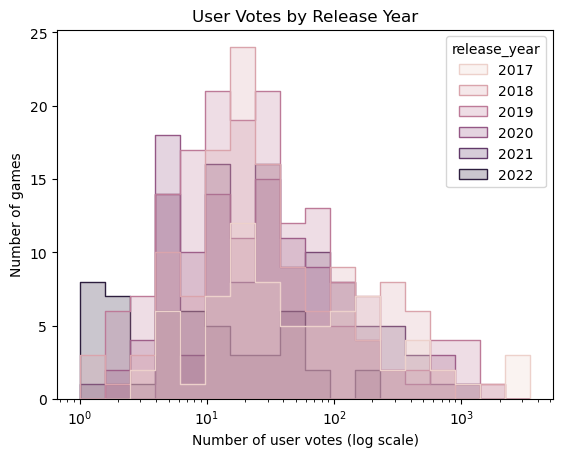

In [17]:
# Create and label the histogram comparison.
sns.histplot(
    data=q2_df,
    x="votes",
    hue="release_year",
    hue_order=year_order,
    element="step",
    log_scale=(True, False),
)

plt.title("User Votes by Release Year")
plt.xlabel("Number of user votes (log scale)")
plt.ylabel("Number of games")
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Most games sit between about 1 and 100 votes, with a long right tail into the hundreds and low thousands. 2017 reaches furthest, with one game near 3,500 votes, while 2022 is crowded at the low end, with most games under about 20. The years overlap a lot between about 10 and 100 votes, so the colors mix in the middle. Two things limit the visual comparison: the 22 zero-vote games can’t show up on a log axis, and the groups are different sizes (58 to 161 games), so taller bars don’t always mean more games in that range.

In [18]:
# Display grouped .describe() summaries and calculate...
q2_df.groupby("release_year")["votes"].describe().round(2).reindex(year_order)

,count,mean,std,min,25%,50%,75%,max
release_year,,,,,,,,
2017,71.0,242.17,609.50,3.0,18.5,35.0,156.5,3497.0
2018,126.0,97.87,198.62,1.0,13.0,21.5,78.0,1573.0
2019,161.0,98.27,242.35,0.0,8.0,22.0,63.0,1682.0
2020,114.0,70.83,175.57,0.0,7.0,18.5,49.0,1214.0
2021,107.0,75.72,135.86,0.0,11.5,26.0,77.0,952.0
2022,58.0,19.19,37.62,0.0,1.0,5.0,17.5,209.0


In [19]:
#  or display the IQR for each group.
q2_iqr = (
    q2_df.groupby("release_year")["votes"].quantile(0.75)
    - q2_df.groupby("release_year")["votes"].quantile(0.25)
)

q2_iqr.reindex(year_order)

release_year
2017    138.0
2018     65.0
2019     55.0
2020     42.0
2021     65.5
2022     16.5
Name: votes, dtype: float64

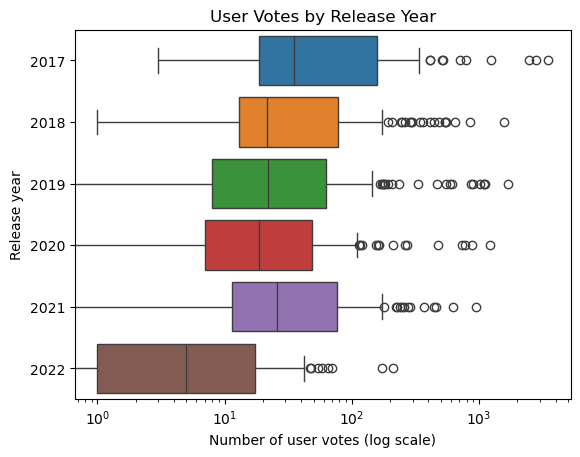

In [20]:
# Create and label the box-plot comparison.
q2_df["release_year_label"] = q2_df["release_year"].astype(str)
year_labels = [str(year) for year in year_order]

sns.boxplot(data=q2_df,
            x="votes",
            y="release_year_label",
            order=year_labels,
            hue="release_year_label",
            hue_order=year_labels)

plt.xscale("log")

plt.title("User Votes by Release Year")
plt.xlabel("Number of user votes (log scale)")
plt.ylabel("Release year")
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The summaries match what I saw. The median falls from 35 votes in 2017 to 21.5 in 2018, 22 in 2019, 18.5 in 2020, 26 in 2021, and then 5 in 2022. So 2018–2021 are similar in the middle, and 2022 drops off. Spread separates them more clearly: the IQR is 138 votes in 2017, 65 in 2018, 55 in 2019, 42 in 2020, 65.5 in 2021, and 16.5 in 2022. 2017 has the widest middle half (18.5 to 156.5 votes) and the largest maximum (3,497), while 2022 is the tightest (1 to 17.5) and tops out at 209. The means are much higher than the medians in every year — 242.17 versus 35 in 2017 — because a handful of popular games pull the average up.

The box plot on the log axis makes the centers and the shrinking spread easier to compare, and the boxes step down from 2017 to 2022 with a small bump in 2021. What it hides is how many games sit at each value, and the zero-vote games can’t be drawn on a log axis. The histogram shows 2022 piling up at the bottom, which the box plot only hints at.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [21]:
# Perform a targeted check against original records or the declared group definitions.
q2_df.sort_values("votes", ascending=False).head(10)[["title", "release_date", "release_year", "num_votes", "votes"]]
print("Analyzed rows:", len(q2_df))
print("Group counts sum:", q2_df["release_year"].value_counts().sum())
print("Zero-vote games:", (q2_df["votes"] == 0).sum())
print("Negative votes:", (q2_df["votes"] < 0).sum())
q2_df.loc[q2_df["num_votes"].astype(str).str.contains(" "),
         ["title", "num_votes", "votes"]]

Analyzed rows: 637
Group counts sum: 637
Zero-vote games: 22
Negative votes: 0


,title,num_votes,votes
257,Animal Crossing: New Horizons,1 214,1214
296,Pokémon Sword and Shield,1 095,1095
314,Luigis Mansion 3,1 012,1012
348,The Legend of Zelda: Links Awakening,1 096,1096
384,Super Mario Maker 2,1 682,1682
443,New Super Mario Bros. U Deluxe,1 116,1116
451,Super Smash Bros. Ultimate,1 573,1573
599,Super Mario Odyssey,3 497,3497
621,Splatoon 2,1 244,1244
628,Mario Kart 8 Deluxe,2 460,2460


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I checked the top of the distribution first. The highest counts are Super Mario Odyssey (3,497 votes), Breath of the Wild (2,782), and Mario Kart 8 Deluxe (2,460), all 2017 releases, so the long tail is real and the log axis isn’t inventing it. The values that use spaces as thousands separators convert correctly — 3 497 becomes 3497 and 1 682 becomes 1682 — and there are 11 of them.

Then I reconciled the counts. All 637 rows have a release date and a vote count, the six year counts add up to 637, and no votes are negative. The 22 zero-vote games are real zeros, not blanks, which is why I kept them. The log axis covers the nonzero range from 1 to 3,497 but can’t show those 22 zeros, which is the main mismatch between the plot and the summaries.

I’d be suspicious if a large value came from a parsing error or if the year counts didn’t add up. Neither happened. What I can’t check is when each vote count was scraped, so a 2022 game’s low count may partly reflect how recently it was reviewed.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: Older games do tend to have more votes, but it isn’t a steady decline. 2017 has the highest center (median 35 votes) and by far the widest spread: IQR 138 votes, middle half from 18.5 to 156.5, and a tail up to 3,497. 2018 through 2021 sit close together, with medians of 21.5, 22, 18.5, and 26 votes and IQRs of 65, 55, 42, and 65.5, so those four years overlap heavily. 2022 is the clear low group, with a median of 5 votes and an IQR of 16.5, and no game above 209 votes. The groups also differ in size (58 to 161 games), which makes the spreads for the smaller years less stable.

This matches my prediction in direction but not in shape. I expected older years to be higher and newer years lower, and that held at the ends. I didn’t expect 2018–2021 to be almost flat while 2022 drops so far below them.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn’t conclude that newer games are less popular, or that release year causes more votes. A game’s vote count depends on how long it has been online, so age and votes are mechanically linked — this is mostly a recency effect, not a measure of quality or audience size. The data also stop in September 2022, so 2022 is a partial year and its games had only a few months to collect votes. The sample is Nintendo Life reviewed games, not all Switch games. Votes are also self-selected: only people who visit the page and choose to vote are counted, so a game with a small but dedicated fan base can look bigger than it is. And the medians hide how skewed the counts are — one game with 3,497 votes barely moves the median but pulls the mean up to 242 for 2017.

## Investigation 3

### Step 1: Question


**What is research question 3? Name the quantitative feature, its units, and the categorical groups.**

Your answer: My third question is whether user ratings differ by genre. I’ll compare the distribution of user rating across the same broad genre families: Action/Adventure, RPG, Sports/Racing, Strategy/Simulation, Party/Music, and Puzzle/Other. The quantitative feature is user rating on a 0–10 scale, and the categorical feature is broad genre. The population is Nintendo Life reviewed Switch games that have enough votes to receive a rating.

**Before calculating or plotting, what do you predict about center, spread, shape, or overlap? Why?**

Your answer: I expect the medians to be fairly close, since most games with enough votes to be rated probably land in the 6–8 range. I expect RPG and Action/Adventure to be a little higher, maybe around 7.5, and Sports/Racing and Party/Music lower, since annual sports titles and party games often get more mixed reviews. I expect the spreads to be similar, around 1 to 1.5 points, with a lot of overlap, and I expect a few low ratings as outliers rather than a long tail in both directions.

### Step 2: Data

Reuse the initial inspection. Define this question's observations and groups before generating evidence. Preserve the original DataFrame and explain any filtering, conversions, or derived labels.


**Which records and features will you use? Define group labels and units, explain missing-value handling and exclusions, and state what one analyzed observation represents.**

Your answer: I’ll work from a copy of switch_games_df, so the original stays unchanged. One analyzed observation is one Nintendo Switch game review with a usable user rating, not one vote. The quantitative feature is user rating on a 0–10 scale, and the categorical feature is the same six broad genre families I used for question 1. I exclude games with rating = 0, because 0 is the documented missing code for games that didn’t meet the vote threshold — it isn’t a real score, so this is a missing-value exclusion rather than filtering out low ratings. I also exclude the blank genres, same as before. I’m not filtering on vote count for this question.

In [22]:
# Prepare this question's analysis DataFrame and preview the selected features.
q3_df = switch_games_df.copy()

q3_df["broad_genre"] = q3_df["genre"].apply(broad_genre)

q3_df = q3_df.loc[
    q3_df["broad_genre"].notna() & (q3_df["rating"] > 0)
].copy()

q3_df[["title", "genre", "broad_genre", "num_votes", "rating"]].head()

,title,genre,broad_genre,num_votes,rating
3,Temtem,Action Adventure RPG,Action/Adventure,5,7.8
5,Splatoon 3,Action,Action/Adventure,42,9.1
6,JoJos Bizarre Adventure: All-Star Battle R,Fighting,Action/Adventure,3,7.0
8,Pac-Man World Re-PAC,Action Adventure Platformer,Action/Adventure,9,6.9
9,Teenage Mutant Ninja Turtles: The Cowabunga Co...,Action Arcade Fighting Platformer,Action/Adventure,13,6.9


In [23]:
# Display the number of usable observations in each group.
q3_df["broad_genre"].value_counts().reindex(genre_order)

broad_genre
Action/Adventure       427
RPG                     43
Sports/Racing           40
Strategy/Simulation     18
Party/Music             22
Puzzle/Other            22
Name: count, dtype: int64

### Step 3: Evidence

Create a **histogram comparison and a box-plot comparison** for this quantitative feature using the same observations and group definitions. A violin plot is optional. Use descriptive titles, units, readable labels, a consistent group order, and named colors. Keep group colors consistent across plots. Use shared histogram bins; use whole-number bins when appropriate for discrete counts. Label whether the vertical axis shows counts or another documented scale.

Start with the histogram and estimate the distributions visually. Then calculate group summaries and use the box plot to compare them. Retain valid extreme observations; do not remove them just to make figures look cleaner.


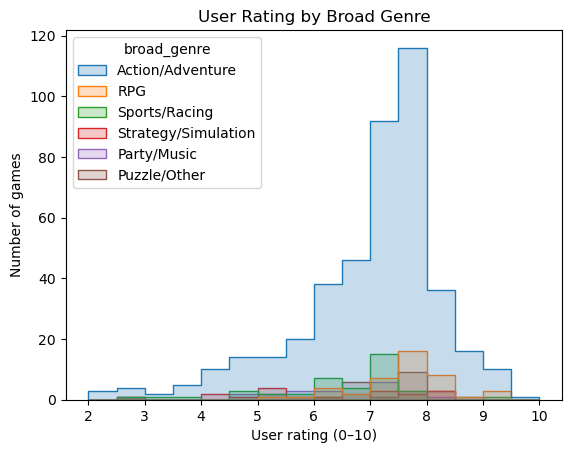

In [24]:
# Create and label the histogram comparison.
sns.histplot(
    data=q3_df,
    x="rating",
    hue="broad_genre",
    hue_order=genre_order,
    bins=16,
    binrange=(2, 10),
    element="step",
)

plt.title("User Rating by Broad Genre")
plt.xlabel("User rating (0–10)")
plt.ylabel("Number of games")
plt.show()

**From the histogram, estimate each group's typical values and spread. Describe shape, overlap, and unusual observations. How do group sizes affect the comparison?**

Your answer: Most ratings sit between about 6 and 8, and the groups overlap heavily there. Action/Adventure has the tallest bars around 7–8, which fits its 427 games. RPG looks shifted slightly right, with most ratings between 7 and 8, while Strategy/Simulation is the flattest and spreads from about 5 to 8. Sports/Racing and Party/Music sit a little lower, mostly 6 to 7.5, and Puzzle/Other clusters around 7 to 8. A few games rate near 2–3 in Action/Adventure and Strategy/Simulation, which stretch those lower tails. The group sizes are very uneven — 18 to 427 games — so the small groups have short bars and are hard to compare by height.

In [25]:
# Display grouped .describe() summaries and calculate...
q3_df.groupby("broad_genre")["rating"].describe().round(2).reindex(genre_order)

,count,mean,std,min,25%,50%,75%,max
broad_genre,,,,,,,,
Action/Adventure,427.0,6.96,1.29,2.3,6.40,7.30,7.80,9.6
RPG,43.0,7.58,0.84,5.2,7.30,7.70,8.00,9.4
Sports/Racing,40.0,6.41,1.33,2.8,5.95,6.90,7.22,9.0
Strategy/Simulation,18.0,6.07,1.69,2.5,5.15,5.75,7.70,8.2
Party/Music,22.0,6.57,1.02,4.7,5.90,6.80,7.28,8.4
Puzzle/Other,22.0,7.23,1.16,2.9,6.80,7.50,7.80,8.5


In [26]:
# or display the IQR for each group.
q3_iqr = (
    q3_df.groupby("broad_genre")["rating"].quantile(0.75)
    - q3_df.groupby("broad_genre")["rating"].quantile(0.25)
)

q3_iqr.reindex(genre_order)

broad_genre
Action/Adventure       1.400
RPG                    0.700
Sports/Racing          1.275
Strategy/Simulation    2.550
Party/Music            1.375
Puzzle/Other           1.000
Name: rating, dtype: float64

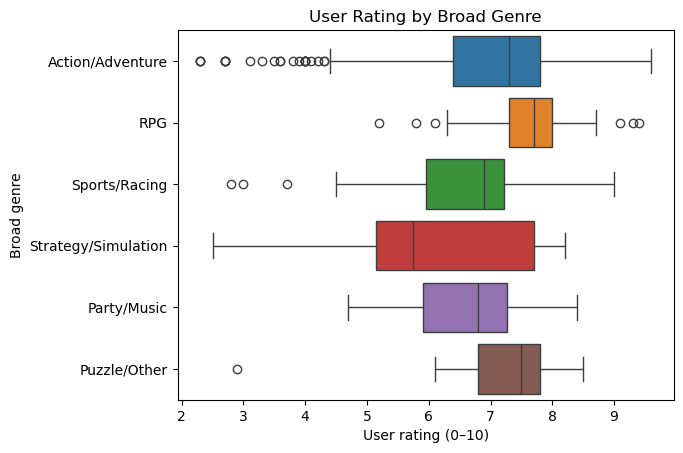

In [27]:
# Create and label the box-plot comparison.
sns.boxplot(data=q3_df,
            x="rating",
            y="broad_genre",
            order=genre_order,
            hue="broad_genre",
            hue_order=genre_order)

plt.title("User Rating by Broad Genre")
plt.xlabel("User rating (0–10)")
plt.ylabel("Broad genre")
plt.show()

**How do the calculated summaries compare with your visual estimates? Which groups look similar or different? Cite centers and spreads with units, and explain what each plot reveals or hides.**

Your answer: The summaries match what I saw. RPG has the highest median (7.70) and a tight IQR of 0.70 (7.30 to 8.00), so its ratings cluster in a narrow band. Puzzle/Other is next (median 7.50, IQR 1.00), and Action/Adventure is just behind (7.30, IQR 1.40), though it has the widest range (2.3 to 9.6) because of a few low-rated games. Sports/Racing (6.90, IQR of about 1.3) and Party/Music (6.80, IQR of about 1.4) are close together and lower. Strategy/Simulation has the lowest median (5.75) and the widest spread (IQR 2.55, 5.15 to 7.70), but it also has the smallest group (18 games), so that spread is less stable.

The box plot makes the ordering clear: RPG and Puzzle/Other sit highest, Action/Adventure is just below with a longer lower tail, and Strategy/Simulation is visibly lower and wider. What the box plot hides is how concentrated the ratings are — almost every group has most of its games between 6 and 8, which the histogram shows. It also hides group size, so the 18-game Strategy/Simulation group looks as important as the 427-game Action/Adventure group.

### Step 4: Check

Perform a sanity check connected to this question. Inspect original records for unusual values, verify any group boundaries or conversions, and reconcile group counts with the selected data. Consider plausible units, whether zero or negative values are valid, and whether the plotted range matches the numerical summary. Do not simply repeat the initial missing-value count.


In [28]:
# Perform a targeted check against original records or the declared group definitions.
check_df = switch_games_df.copy()
check_df["votes"] = pd.to_numeric(
    check_df["num_votes"].str.replace(" ", "", regex=False),
    errors="coerce"
)

check_df.groupby(check_df["rating"] == 0)["votes"].agg(["count", "min", "max"])
print("Original rows:", len(switch_games_df))
print("Zero ratings:", (switch_games_df["rating"] == 0).sum())
print("Rated rows:", (switch_games_df["rating"] > 0).sum())
print("Analyzed rows:", len(q3_df))
print("Group counts sum:", q3_df["broad_genre"].value_counts().sum())
q3_df.sort_values("rating").head(8)[["title", "genre", "broad_genre", "num_votes", "rating"]]

Original rows: 637
Zero ratings: 51
Rated rows: 586
Analyzed rows: 572
Group counts sum: 572


,title,genre,broad_genre,num_votes,rating
214,Bounty Battle,Action Arcade Fighting,Action/Adventure,10,2.3
311,Close To The Sun,Adventure,Action/Adventure,3,2.3
303,Race With Ryan,Arcade Party Racing,Action/Adventure,9,2.3
433,RIOT - Civil Unrest,Simulation Strategy,Strategy/Simulation,4,2.5
390,PixARK,Action Adventure RPG,Action/Adventure,3,2.7
325,Ice Age: Scrats Nutty Adventure,Action Adventure,Action/Adventure,3,2.7
309,Beast Quest,Action Adventure,Action/Adventure,3,2.7
145,BIG-Bobby-Car - The Big Race,Adventure Racing,Action/Adventure,3,2.7


**What would make you suspicious, and why? What did your check establish? Describe any correction or unresolved uncertainty.**

Your answer: I checked whether the zero codes line up with the vote threshold. All 51 games with rating = 0 have 0, 1, or 2 votes, and every game with 3 or more votes has a nonzero rating. That matches the data dictionary, which says a rating is only calculated once a game passes a vote threshold, so dropping the zeros removes missing values rather than real zero scores.

I also reconciled the counts. The file has 637 rows, and 51 have rating = 0, leaving 586 rated games. Fourteen of those have a blank genre, so 572 go into the analysis, and the six group counts add up to 572.

I looked at the low end too. The lowest ratings (2.2 to 2.7) are real games like FIFA 22, Bounty Battle, and Race With Ryan, with 3 to 32 votes, so they aren’t data-entry artifacts. The scale is also clearly 0–10, not 0–100, since the highest rating is 9.6.

I’d be suspicious if a 0 rating had a healthy vote count, if a rated game had only 0–2 votes, or if the group counts didn’t reconcile. None of that happened. The one uncertainty is that the page only says “exceeded a threshold,” so I inferred the cutoff of 3 votes from the data rather than reading it directly.

### Step 5: Conclusion


**Answer your research question using group sizes, center, spread, and overlap. Cite numerical evidence with units. How does it compare with your prediction?**

Your answer: User rating does differ by genre, but most groups are close. RPG has the highest median (7.70) and the narrowest spread (IQR 0.70, 7.30 to 8.00), so its 43 games rate consistently well. Puzzle/Other is just behind (median 7.50, IQR 1.00, 22 games). Action/Adventure has a slightly lower median (7.30) but a wider IQR of 1.40 and the widest range (2.3 to 9.6), so its 427 games include the highest-rated title and some very low-rated ones. Sports/Racing (median 6.90) and Party/Music (6.80) sit lower, with spreads of about 1.3 and 1.4 points. Strategy/Simulation has the lowest median (5.75) and by far the widest spread (IQR 2.55, 5.15 to 7.70), but only 18 games. Even so, most groups overlap between about 6.5 and 7.8.

This partly matches my prediction. I expected RPG and Action/Adventure to be high, and RPG was highest, but Action/Adventure ended up mid-pack because of its low-rated games. I expected Sports/Racing and Party/Music to be lower, which they were. I didn’t expect Strategy/Simulation to be the lowest with such a wide spread, though its small group makes that uncertain.

### Step 6: Limitation


**What should a reader avoid concluding, and why? Connect the limitation to this question and dataset.**

Your answer: A reader shouldn’t conclude that genre causes better or worse ratings, or that these numbers represent all Switch players. The ratings come only from Nintendo Life visitors who chose to vote, so they’re self-selected and can be skewed by a small number of fans. The data also drop every game with fewer than 3 votes, which removes a lot of obscure titles and may make the remaining games look better than the full catalogue. The small groups matter most: Strategy/Simulation has 18 games, and Party/Music and Puzzle/Other have 22, so one or two titles can move the median. My broad genre grouping also mixes different games — an “Action RPG” lands in Action/Adventure rather than RPG — and ratings are only given to one decimal, so differences under about half a point shouldn’t be read as meaningful.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: I used AI to help plan the code and draft some of the wording. One suggestion I modified was how to handle genre. The first version kept the raw multi-label strings, but that left too many tiny groups, so I grouped them into six broad families using the first listed genre and excluded the blank ones. I also checked the rating = 0 rows against the vote counts myself: all 51 zero ratings had 0, 1, or 2 votes, and every game with 3 or more votes had a rating, which confirmed they were missing values rather than real scores. I rejected using system as a group because it was 630 games versus 7, and I checked the group counts and summaries against the printed output.

## Submission checklist

- Include the new dataset CSV, source citation, dictionary reference, and explanation of why it has not been used in class or a previous lab.
- Document every feature, including meaning, units/codes, conceptual type, storage type, and missing count.
- Identify at least one categorical feature and three distinct quantitative features.
- Complete three different questions, one quantitative feature per question, each with a prediction and all six workflow steps.
- Include a histogram and box plot for each question, grouped summaries and IQRs, and usable group sizes.
- Explain preparation and exclusions; preserve valid extreme values and distinguish missing values from zero.
- Support conclusions about similarities or differences with numerical and visual evidence, contextual checks, and specific limitations.
- Complete every written response and the AI-use reflection.
- Restart the kernel and run every cell in order; use relative paths and ensure all claims match the output.
